In [1]:
import pandas as pd

trades = pd.read_csv("../data/raw/Allocation_Trades.csv", low_memory=False)
print(trades.shape)
print(trades.columns.tolist())
trades.head()

(488877, 17)
['resource_type', 'origin_state', 'origin_water_system', 'origin_trading_zone_or_WRPA', 'dest_state', 'dest_water_system', 'dest_trading_zone_or_WRPA', 'unit_of_measure', 'quantity_traded', 'net_price', 'price_per_ML', 'date_of_approval', 'regulated_unregulated', 'drainage_division', 'murray_darling_basin_region', 'qld_origin_trading_zone', 'qld_destination_trading_zone']


,resource_type,origin_state,origin_water_system,origin_trading_zone_or_WRPA,dest_state,dest_water_system,dest_trading_zone_or_WRPA,unit_of_measure,quantity_traded,net_price,price_per_ML,date_of_approval,regulated_unregulated,drainage_division,murray_darling_basin_region,qld_origin_trading_zone,qld_destination_trading_zone
0,Surface water,Victoria,VIC Murray (SS2),6 VIC Murray - Dart to Barmah,Victoria,Goulburn (SS6),1A Greater Goulburn,ML,10.0,0,0,15-09-2009,regulated,Murray-Darling Basin,Southern MDB,NaN,NaN
1,Surface water,Victoria,VIC Murray (SS2),7 VIC Murray - Barmah to SA,Victoria,VIC Murray (SS2),7 VIC Murray - Barmah to SA,ML,0.2,0,0,16-09-2009,regulated,Murray-Darling Basin,Southern MDB,NaN,NaN
2,Surface water,Victoria,VIC Murray (SS2),7 VIC Murray - Barmah to SA,Victoria,VIC Murray (SS2),7 VIC Murray - Barmah to SA,ML,2.7,999,370,16-09-2009,regulated,Murray-Darling Basin,Southern MDB,NaN,NaN
3,Surface water,Victoria,VIC Murray (SS2),7 VIC Murray - Barmah to SA,Victoria,VIC Murray (SS2),7 VIC Murray - Barmah to SA,ML,0.5,185,370,16-09-2009,regulated,Murray-Darling Basin,Southern MDB,NaN,NaN
4,Surface water,Victoria,VIC Murray (SS2),6 VIC Murray - Dart to Barmah,Victoria,VIC Murray (SS2),6 VIC Murray - Dart to Barmah,ML,18.0,0,0,16-09-2009,regulated,Murray-Darling Basin,Southern MDB,NaN,NaN


In [2]:
dates = pd.to_datetime(trades["date_of_approval"], dayfirst=True, errors="coerce")
dates.min(), dates.max()

(Timestamp('2008-07-01 00:00:00'), Timestamp('2026-11-09 00:00:00'))

In [3]:
trades["date"] = dates
print("Dates illisibles :", dates.isna().sum())
print("Part des prix à 0 $ :", (trades["price_per_ML"] == 0).mean())
trades["murray_darling_basin_region"].value_counts()

Dates illisibles : 0
Part des prix à 0 $ : 0.44807180538254


murray_darling_basin_region
Southern MDB       423163
Northern MDB        16744
MDB Groundwater     12467
Name: count, dtype: int64

In [4]:
south = trades[
    (trades["murray_darling_basin_region"] == "Southern MDB")
    & (trades["resource_type"] == "Surface water")
    & (trades["price_per_ML"] > 0)
].copy()

print(south.shape)
south["origin_trading_zone_or_WRPA"].value_counts().head(40)

(242908, 18)


origin_trading_zone_or_WRPA
7 VIC Murray - Barmah to SA                                                                                                                                                    59986
1A Greater Goulburn                                                                                                                                                            58277
Murray Irrigation                                                                                                                                                              35935
Murrumbidgee Regulated River Water Source                                                                                                                                      17958
6 VIC Murray - Dart to Barmah                                                                                                                                                  16430
New South Wales Murray Regulated River Water Source / that part of 

In [5]:
def to_region(zone):
    z = str(zone)
    if z.startswith("1A") or z.startswith("2") or z.startswith("3 ") or z == "Broken":
        return "VIC Goulburn-Broken"
    if z.startswith("1B") or z.startswith("4") or z.startswith("5"):
        return "VIC Loddon-Campaspe"
    if z.startswith("6"):
        return "VIC Murray Above"
    if z.startswith("7"):
        return "VIC Murray Below"
    if "upstream of the River Murray at Picnic Point" in z or z == "Murray Irrigation":
        return "NSW Murray Above"
    if "downstream of the River Murray at Picnic Point" in z:
        return "NSW Murray Below"
    if z.startswith("Lower Darling"):
        return "NSW Lower Darling"
    if "Murrumbidgee" in z or "Coleambally" in z:
        return "NSW Murrumbidgee"
    if z.startswith("River Murray Prescribed") or z.startswith("CIT"):
        return "SA Murray"
    return None

south["Region"] = south["origin_trading_zone_or_WRPA"].apply(to_region)
print("Part non classée :", south["Region"].isna().mean())
south["Region"].value_counts()

Part non classée : 0.034527475422793816


Region
VIC Goulburn-Broken    60498
VIC Murray Below       59986
NSW Murray Above       38001
NSW Murrumbidgee       20454
VIC Murray Above       18488
SA Murray              15242
NSW Murray Below       15106
VIC Loddon-Campaspe     6239
NSW Lower Darling        507
Name: count, dtype: int64

In [6]:
south["Year"] = south["date"].dt.year + (south["date"].dt.month >= 7).astype(int)

print(south["price_per_ML"].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]))
print("Part sous 5 $ :", (south["price_per_ML"] < 5).mean())

count    242908.000000
mean        204.549076
std        1701.675046
min           1.000000
1%            1.000000
5%           12.000000
50%         129.000000
95%         550.000000
99%         800.000000
max      620000.000000
Name: price_per_ML, dtype: float64
Part sous 5 $ : 0.01995817346485089


In [7]:
clean = south[(south["price_per_ML"] >= 5) & (south["price_per_ML"] <= 2000)].copy()
print("Ventes gardées :", len(clean), "sur", len(south))

clean["value"] = clean["price_per_ML"] * clean["quantity_traded"]

prices = clean.groupby(["Year", "Region"]).agg(
    value=("value", "sum"),
    volume=("quantity_traded", "sum"),
    n_trades=("price_per_ML", "size"),
).reset_index()

prices["P_nominal"] = prices["value"] / prices["volume"]
prices.head(12)

Ventes gardées : 237808 sur 242908


,Year,Region,value,volume,n_trades,P_nominal
0,2009,NSW Murray Above,1.637748e+07,54921.000,1833,298.200761
1,2009,NSW Murrumbidgee,9.010156e+07,256897.300,2288,350.729866
2,2009,VIC Goulburn-Broken,2.750894e+07,86181.700,2852,319.196961
3,2009,VIC Loddon-Campaspe,5.512335e+06,15521.600,207,355.139586
4,2009,VIC Murray Above,8.060422e+06,23967.700,830,336.303542
5,2009,VIC Murray Below,1.432048e+07,43455.000,1922,329.547327
6,2010,NSW Murray Above,9.067614e+06,61168.000,1137,148.241139
7,2010,NSW Murrumbidgee,1.404511e+07,87109.000,642,161.236072
8,2010,SA Murray,2.198723e+06,16005.829,518,137.370163
9,2010,VIC Goulburn-Broken,1.886272e+07,115824.100,2248,162.856570


In [8]:
cpi_raw = pd.read_excel("../data/raw/abs_cpi_quarterly.xlsx", sheet_name="Data1", index_col=0)

col = [c for c in cpi_raw.columns
       if "index numbers" in str(c).lower()
       and "all groups cpi" in str(c).lower()
       and "australia" in str(c).lower()][0]
print("Colonne choisie :", col)

cpi = cpi_raw[col].iloc[9:].astype(float)
cpi.index = pd.to_datetime(cpi.index)

cpi_year = cpi.groupby(cpi.index.year + (cpi.index.month >= 7).astype(int)).mean()
cpi_year.tail()

Colonne choisie : Index Numbers ;  All groups CPI ;  Australia ;


2023     91.2500
2024     95.0725
2025     97.3900
2026    101.0150
2027    103.6400
Name: Index Numbers ;  All groups CPI ;  Australia ;, dtype: float64

In [9]:
base = cpi_year.loc[2020]   # 2020 = juillet 2019 à juin 2020

prices["CPI"] = prices["Year"].map(cpi_year)
prices["P_real"] = prices["P_nominal"] * base / prices["CPI"]

prices[prices["Year"].isin([2009, 2020, 2026])]

,Year,Region,value,volume,n_trades,P_nominal,CPI,P_real
0,2009,NSW Murray Above,1.637748e+07,54921.000,1833,298.200761,64.3275,372.348228
1,2009,NSW Murrumbidgee,9.010156e+07,256897.300,2288,350.729866,64.3275,437.938667
2,2009,VIC Goulburn-Broken,2.750894e+07,86181.700,2852,319.196961,64.3275,398.565122
3,2009,VIC Loddon-Campaspe,5.512335e+06,15521.600,207,355.139586,64.3275,443.444863
4,2009,VIC Murray Above,8.060422e+06,23967.700,830,336.303542,64.3275,419.925246
5,2009,VIC Murray Below,1.432048e+07,43455.000,1922,329.547327,64.3275,411.489102
90,2020,NSW Lower Darling,2.666400e+04,344.400,7,77.421603,80.3225,77.421603
91,2020,NSW Murray Above,2.571686e+07,50330.520,1086,510.959620,80.3225,510.959620
92,2020,NSW Murray Below,1.132156e+08,167662.700,1048,675.258001,80.3225,675.258001
93,2020,NSW Murrumbidgee,7.872042e+07,146977.900,1014,535.593584,80.3225,535.593584


In [10]:
abares = pd.read_excel("../data/raw/abares_mdb_supply_2021.xlsx", sheet_name="Supply")[["Year", "Region", "P"]]

check = prices.merge(abares, on=["Year", "Region"], how="inner")
print("Paires région-année en commun :", len(check))
print("Corrélation :", check["P_real"].corr(check["P"]))
print("Écart médian (BOM / ABARES - 1) :", (check["P_real"] / check["P"]).median() - 1)

Paires région-année en commun : 108
Corrélation : 0.9792870875496923
Écart médian (BOM / ABARES - 1) : -0.040815719692134045


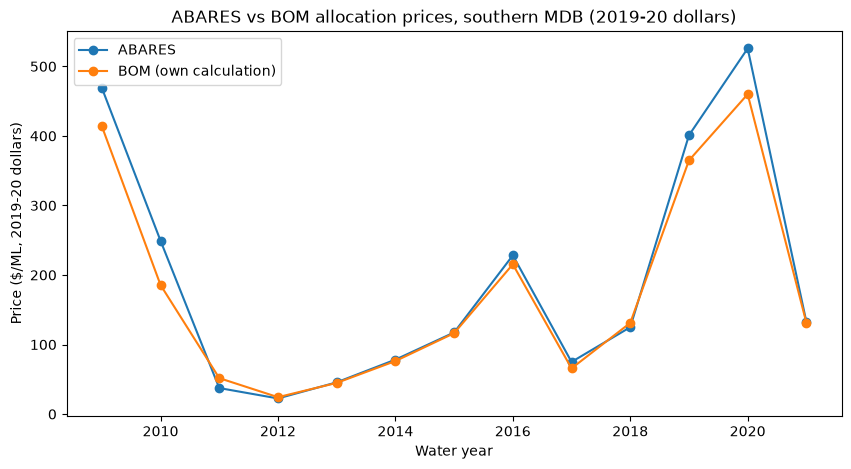

In [11]:
by_year = check.groupby("Year")[["P", "P_real"]].mean()

ax = by_year.plot(marker="o", figsize=(10, 5),
                  title="ABARES vs BOM allocation prices, southern MDB (2019-20 dollars)")
ax.set_ylabel("Price ($/ML, 2019-20 dollars)")
ax.set_xlabel("Water year")
ax.legend(["ABARES", "BOM (own calculation)"])
ax.figure.savefig("../figures/overlap_check.png", dpi=150, bbox_inches="tight")

In [12]:
prices.to_csv("../data/processed/bom_prices.csv", index=False)

**Overlap check (2009-2021):** BOM prices, computed as volume-weighted averages of
allocation trades and converted to 2019-20 dollars with the ABS CPI, track ABARES
prices closely (correlation 0.98 across 108 region-years, median gap -4%).
BOM prices are 10-15% lower in drought years (2009-10, 2019-20). The BOM series
can therefore be used to extend the ABARES data to 2026.